# 
Time Series Models: AR, MA, ARIMA

## Autoregressive Model (AR)

**Definition**:  
An AR model regresses a variable on its own past values:

$$
Y_t = \phi_1 Y_{t-1} + \phi_2 Y_{t-2} + \dots + \phi_p Y_{t-p} + u_t
$$


## 2. Moving Average Model (MA)

**Definition**:  
An MA model expresses \( Y_t \) as a function of past shocks:

$$
Y_t = u_t + \theta_1 u_{t-1} + \theta_2 u_{t-2} + \dots + \theta_q u_{t-q}
$$

## 3. ARIMA Model (Autoregressive Integrated Moving Average)

**Definition**:  
ARIMA(p, d, q) models combine:

- **AR(p)**: Autoregressive part  
- **I(d)**: Integrated part (number of differences to make the series stationary)  
- **MA(q)**: Moving average part  

The general form:

$$
\Delta^d Y_t = \phi_1 \Delta^d Y_{t-1} + \dots + \phi_p \Delta^d Y_{t-p} + u_t + \theta_1 u_{t-1} + \dots + \theta_q u_{t-q}
$$

**Use**: Models non-stationary data that becomes stationary after differencing.

## 4. Augmented Dickey-Fuller (ADF) Test

Used to test whether a time series is **stationary** or has a **unit root**.

### Hypotheses:
$$
( H_0 ): non-stationary
$$
$$
( H_1 ):  stationary
$$

**ADF**
$$
Delta Y_t = \alpha + \beta t + \gamma Y_{t-1} + \sum_{i=1}^p \delta_i \Delta Y_{t-i} + u_t
$$
We test:

$$
- ( H_0: \gamma = 1 ) (unit root)
- ( H_1: \gamma < 1 ) (stationary)
$$
### Decision Rule critical value:

- If ADF test statistic < critical value → **Reject \( H_0 \)** → Stationary  
- If ADF test statistic > critical value → **Fail to reject \( H_0 \)** → Unit root (non-stationary)

Note: Critical values come from the **Dickey-Fuller distribution**, not the standard t-distribution.

### Decision Rule p-value:
- If p-value < 0.05 → **Reject \( H_0 \)** → Stationary  
- If p-value > 0.05 > critical value → **Fail to reject \( H_0 \)** → Unit root (non-stationary)
---

## Definition

A **white noise process** $(\{u_t\})$ is a sequence of random variables satisfying:

1. **Zero Mean**  
   $$
   \mathbb{E}[u_t] = 0
   $$

2. **Constant Variance (Homoskedasticity)**  
   $$
   \mathbb{E}[u_t^2] = \sigma^2 < \infty
   $$

3. **No Serial Correlation (Uncorrelatedness)**  
   $$
   \mathbb{E}[u_t u_s] = 0 \quad \text{for } t \neq s
   $$
---
- **Model Diagnostics**  
  Residuals from a correctly specified model should behave like white noise. If they don't, the model is likely misspecified.

- **Innovation Processes in Time Series**  
  In ARMA models:
  $$
    X_t = \phi X_{t-1} + u_t + \theta u_{t-1}, \quad u_t \sim \text{white noise}
  $$
---

### 📊 ACF and PACF Patterns for ARIMA Models

| Model Type    | ACF Pattern                          | PACF Pattern                          |
|---------------|--------------------------------------|----------------------------------------|
| **AR(p)**     | Tails off (Geometric decay)          | Significant up to lag **p**, then cuts off |
| **MA(q)**     | Significant up to lag **q**, then cuts off | Tails off (Geometric decay)          |
| **ARMA(p, q)**| Tails off (Geometric decay)          | Tails off (Geometric decay)            |

In [ ]:
#ACF: Autocorrelation
#PACF: Partial Autocorrelation

### ARIMA and SARIMA

**Import necessary Libraries**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sms
import pandas as pd
from datetime import datetime
from scipy import stats

**Read the dataset**

In [2]:
df_airline=pd.read_csv("airline_passengers.csv")
df_airline.head()

,Month,Thousands of Passengers
0,1949-01,112.0
1,1949-02,118.0
2,1949-03,132.0
3,1949-04,129.0
4,1949-05,121.0


**Simple EDA**

In [3]:
#missing values
df_airline.isnull().sum()

Month                      0
Thousands of Passengers    1
dtype: int64

**Dealing with missing values**

In [4]:
df_airline.dropna(axis=0,inplace = True) #drop missing values

In [5]:
#outliers values_zscores
z_scores = np.abs(stats.zscore(df_airline["Thousands of Passengers"]))
print(z_scores)

[1.40777884 1.35759023 1.24048348 1.26557778 1.33249593 1.21538918
 1.10664719 1.10664719 1.20702441 1.34922546 1.47469699 1.35759023
 1.38268454 1.29067209 1.16520057 1.21538918 1.29903686 1.09828242
 0.9226223  0.9226223  1.02299951 1.23211871 1.3910493  1.17356534
 1.1317415  1.08991766 0.85570415 0.98117567 0.90589276 0.85570415
 0.68004402 0.68004402 0.80551554 0.98954044 1.12337673 0.95608137
 0.91425753 0.83897462 0.73023263 0.83060985 0.81388031 0.52111343
 0.42073621 0.320359   0.59639634 0.74696217 0.90589276 0.72186786
 0.70513833 0.70513833 0.37054761 0.37891237 0.42910098 0.31199423
 0.1363341  0.06941596 0.36218284 0.57966681 0.83897462 0.66331449
 0.63822018 0.77205647 0.37891237 0.44583052 0.38727714 0.1363341
 0.18152708 0.10624417 0.17815794 0.42910098 0.64658495 0.42910098
 0.320359   0.39564191 0.1112398  0.09451026 0.08614549 0.29026907
 0.7001427  0.55794164 0.26517476 0.05268642 0.36218284 0.01922735
 0.03096126 0.02759212 0.3069986  0.27353953 0.31536337 0.78379

In [6]:
z = pd.DataFrame(z_scores)

<Axes: ylabel='Frequency'>

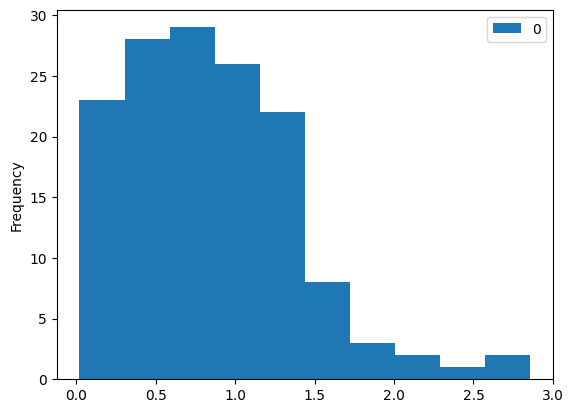

In [7]:
z.plot(kind = "hist")

In [8]:
#duplicated values
df_airline.duplicated().sum()

np.int64(0)

In [9]:
df_airline.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Month                    144 non-null    str    
 1   Thousands of Passengers  144 non-null    float64
dtypes: float64(1), str(1)
memory usage: 2.4 KB


**Change Month type to date**

In [10]:
df_airline["Month"]= pd.to_datetime(df_airline["Month"])

In [11]:
df_airline.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Month                    144 non-null    datetime64[us]
 1   Thousands of Passengers  144 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.4 KB


<Axes: >

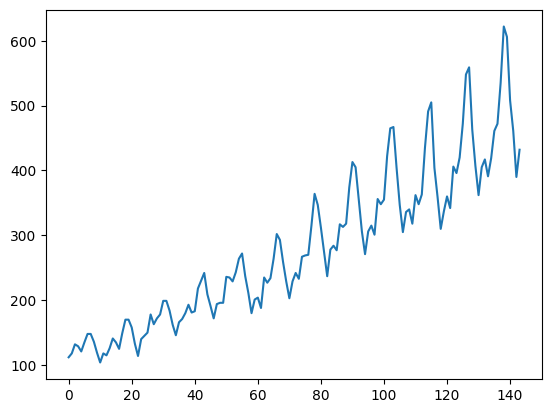

In [12]:
df_airline["Thousands of Passengers"].plot()

**Set index**

In [13]:
df_airline.set_index('Month',inplace=True)

<Axes: xlabel='Month'>

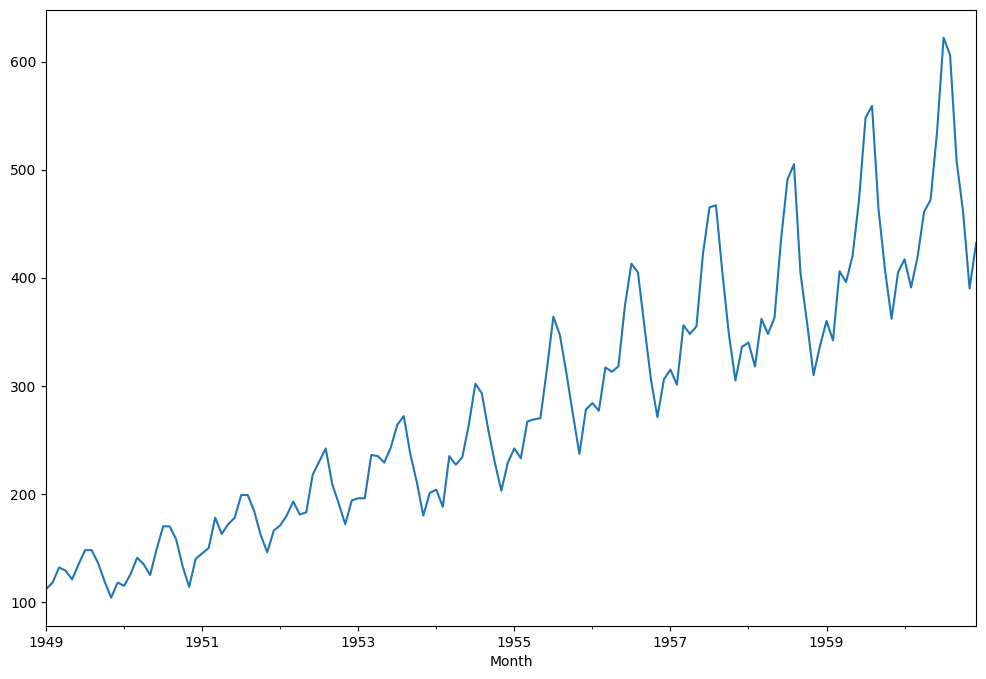

In [14]:
df_airline["Thousands of Passengers"].plot(figsize = (12,8))

### Decomposition

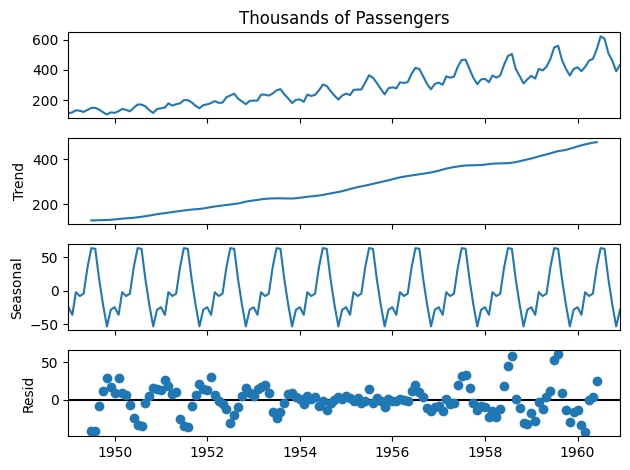

In [15]:
from statsmodels.tsa.seasonal import seasonal_decompose
comp = seasonal_decompose(df_airline["Thousands of Passengers"], model ="additive", period = 12)
comp.plot()
plt.show()

# Modelling SARIMA

### 1. Stationary Analysis

In [16]:
def salem():
    print("السلام عليكم")

In [17]:
salem()

السلام عليكم


In [18]:
def avg(x,y):
    t = (x + y) / 2
    print("average is:", t)

In [19]:
avg(100,65)

average is: 82.5


In [22]:
from statsmodels.tsa.stattools import adfuller, kpss

In [23]:
def adf_test(series):
    result = adfuller(series)
    print(result)
    print("adf Statistics: {}".format(result[0]))
    print("p- value: {}".format(result[1]))
    if result[1] >= 0.05:
        print("strong evidence against the null hypothesis, time series has a unit root. indicating it is non-stationary")
    else:
        print("weak evidence against null hypothesis, fails to reject the null hypothesis. indicating it is stationary ")

### kpss Hypotheses:
$$
( H_0 ): stationary
$$
$$
( H_1 ): non stationary
$$

In [45]:
def kpss_test(series):
    result = kpss(series)
    print(result)
    print("kpss Statistics: {}".format(result[0]))
    print("p- value: {}".format(result[1]))
    if result[1] <= 0.05:
        print("strong evidence against the null hypothesis, time series has a unit root. indicating it is non-stationary")
    else:
        print("weak evidence against null hypothesis, fails to reject the null hypothesis. indicating it is stationary ")

### Check STATIONARY FOR ARMA

LEVEL

**ADF**

In [25]:
adf_test(df_airline["Thousands of Passengers"])

(np.float64(0.8153688792060482), np.float64(0.991880243437641), 13, 130, {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}, np.float64(996.692930839019))
adf Statistics: 0.8153688792060482
p- value: 0.991880243437641
strong evidence against the null hypothesis, time series has a unit root. indicating it is non-stationary


**KPSS**

In [46]:
kpss_test(df_airline["Thousands of Passengers"])

(np.float64(1.6513122354165206), np.float64(0.01), 8, {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739})
kpss Statistics: 1.6513122354165206
p- value: 0.01
strong evidence against the null hypothesis, time series has a unit root. indicating it is non-stationary


C:\Users\Brahim\AppData\Local\Temp\ipykernel_13484\355439486.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(series)


**Philips Perron**

In [26]:
from arch.unitroot import PhillipsPerron

pp = PhillipsPerron(df_airline["Thousands of Passengers"])
print(pp.summary())

First Difference

In [28]:
## Use Techniques Differencing
df_airline["Passengers First Difference"]=df_airline["Thousands of Passengers"]-df_airline["Thousands of Passengers"].shift(1)

In [31]:
adf_test(df_airline["Passengers First Difference"].dropna())

(np.float64(-2.8292668241699994), np.float64(0.0542132902838255), 12, 130, {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}, np.float64(988.5069317854084))
adf Statistics: -2.8292668241699994
p- value: 0.0542132902838255
strong evidence against the null hypothesis, time series has a unit root. indicating it is non-stationary


In [30]:
## Use Techniques Differencing
df_airline["Passengers Second Difference"]=df_airline["Thousands of Passengers"]-df_airline["Thousands of Passengers"].shift(2)

In [32]:
adf_test(df_airline["Passengers Second Difference"].dropna())

(np.float64(-2.9616951355554244), np.float64(0.03862975767698839), 11, 130, {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}, np.float64(985.7309222414161))
adf Statistics: -2.9616951355554244
p- value: 0.03862975767698839
weak evidence against null hypothesis, fails to reject the null hypothesis. indicating it is stationary 


**SO, for ARIMA d = 2**

----

#### SARIMA Stationary

In [38]:
### 12 months 
## Use Techniques Differencing
df_airline["First Difference S"] = df_airline["Thousands of Passengers"]-df_airline["Thousands of Passengers"].shift(12)

In [34]:
adf_test(df_airline["First Difference S"].dropna())

(np.float64(-3.383020726492481), np.float64(0.011551493085514954), 1, 130, {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}, np.float64(919.527129208137))
adf Statistics: -3.383020726492481
p- value: 0.011551493085514954
weak evidence against null hypothesis, fails to reject the null hypothesis. indicating it is stationary 


**SO, for SARIMA D = 1**

---

<Axes: xlabel='Month'>

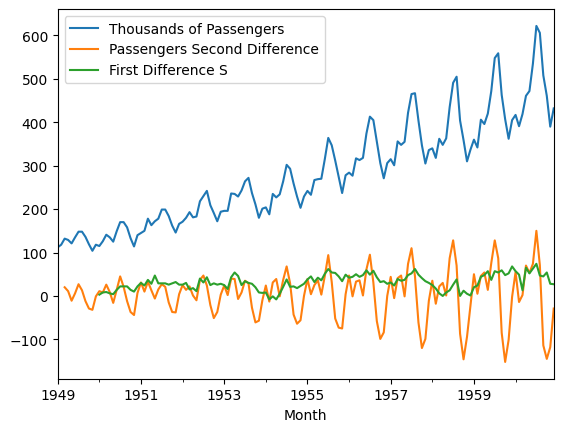

In [37]:
df_airline[["Thousands of Passengers","Passengers Second Difference", "First Difference S"]].plot()

### 2. Detect ACF and PACF ARIMA & SARIMA

**for ARIMA**

In [39]:
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

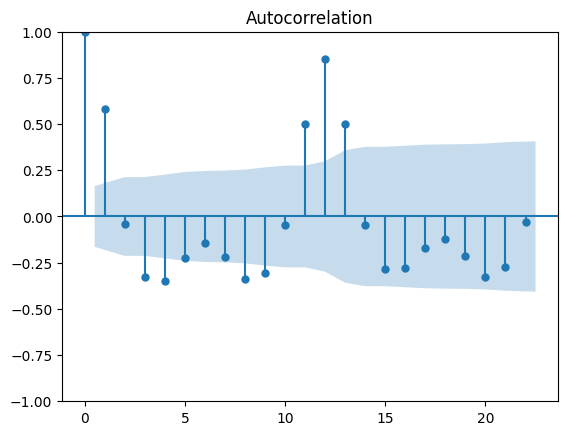

In [41]:
acf = plot_acf(df_airline["Passengers Second Difference"].dropna())

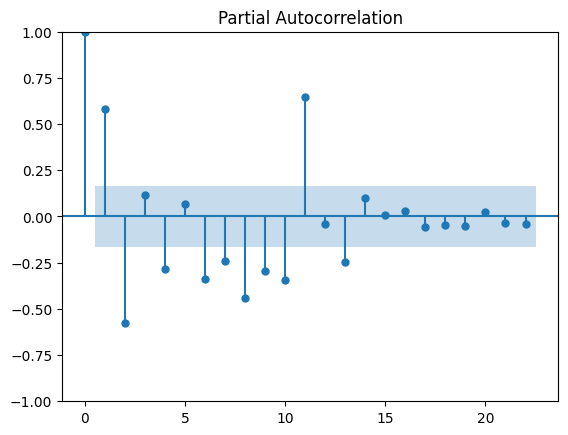

In [42]:
result = plot_pacf(df_airline["Passengers Second Difference"].dropna())

**For SARIMA**

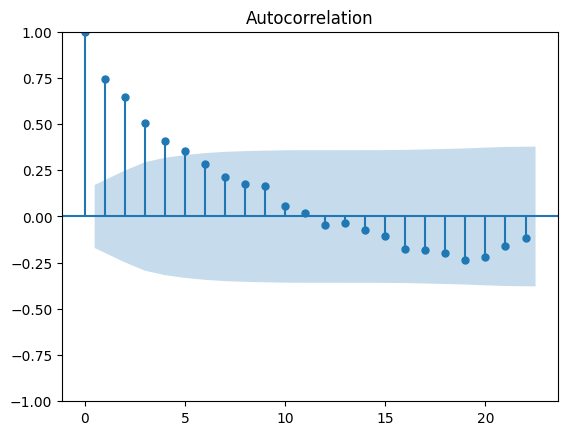

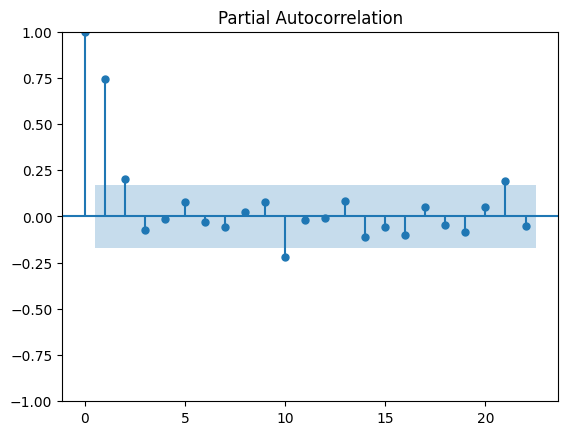

In [43]:
acf12 = plot_acf(df_airline["First Difference S"].dropna())
pacf12 = plot_pacf(df_airline["First Difference S"].dropna())

**We have many models, best model is the model that have:** <br>
1-Less AIC <br>
2-Bigger R squared <br>
3-Less MSE (Mean Squared Error)

---

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

___

### 3. Choose The Best Model

In [44]:
import pmdarima as pm

In [68]:
best_model = pm.auto_arima(
    df_airline['Thousands of Passengers'], 
    start_p=0, max_p=12,     
    d=2,                     
    start_q=0, max_q=12,     
    seasonal=True, m=12,    
    D=1,                    
    max_P=12, max_Q=12,        
    stepwise=True,           
    trace=True)
print(best_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,2,0)(1,1,1)[12]             : AIC=1146.935, Time=0.68 sec
 ARIMA(0,2,0)(0,1,0)[12]             : AIC=1149.749, Time=0.06 sec
 ARIMA(1,2,0)(1,1,0)[12]             : AIC=1079.094, Time=0.41 sec
 ARIMA(0,2,1)(0,1,1)[12]             : AIC=inf, Time=0.90 sec
 ARIMA(1,2,0)(0,1,0)[12]             : AIC=1078.190, Time=0.09 sec
 ARIMA(1,2,0)(0,1,1)[12]             : AIC=1079.232, Time=0.33 sec
 ARIMA(1,2,0)(1,1,1)[12]             : AIC=1080.607, Time=0.82 sec
 ARIMA(2,2,0)(0,1,0)[12]             : AIC=1063.641, Time=0.16 sec
 ARIMA(2,2,0)(1,1,0)[12]             : AIC=1062.635, Time=0.35 sec
 ARIMA(2,2,0)(2,1,0)[12]             : AIC=1062.614, Time=0.72 sec
 ARIMA(2,2,0)(3,1,0)[12]             : AIC=1063.859, Time=1.49 sec
 ARIMA(2,2,0)(2,1,1)[12]             : AIC=inf, Time=5.54 sec
 ARIMA(2,2,0)(1,1,1)[12]             : AIC=1063.105, Time=1.03 sec
 ARIMA(2,2,0)(3,1,1)[12]             : AIC=inf, Time=11.38 sec
 ARIMA(1,2,0)(2,1,0)[12]         

### 4. Fit the best Model

In [50]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [51]:
model_SARIMA =SARIMAX(df_airline['Thousands of Passengers'],order=(5,2,0),seasonal_order=(2,1,0,12))# P,I,Q,F

C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [52]:
model_SARIMA_fit= model_SARIMA.fit()

### 5. Prediction

**5.1 Set start and end date**

In [53]:
##prediction
pred_start_date=df_airline.index[0]
pred_end_date=df_airline.index[-1]
print(pred_start_date)
print(pred_end_date)

1949-01-01 00:00:00
1960-12-01 00:00:00


In [54]:
from datetime import datetime

In [55]:
datetime.now()

datetime.datetime(2026, 7, 27, 18, 9, 48, 332220)

**5.2 Create the prediction using the selected model**

In [56]:
pred_Sarima=model_SARIMA_fit.predict(start=pred_start_date,end=pred_end_date)

**5.3 Create the residuals**

In [57]:
residuals = df_airline["Thousands of Passengers"] - pred_Sarima

**5.4 add prediction values inside the dataset**

In [58]:
df_airline["SARIMA Prediction"] = pred_Sarima

<Axes: xlabel='Month'>

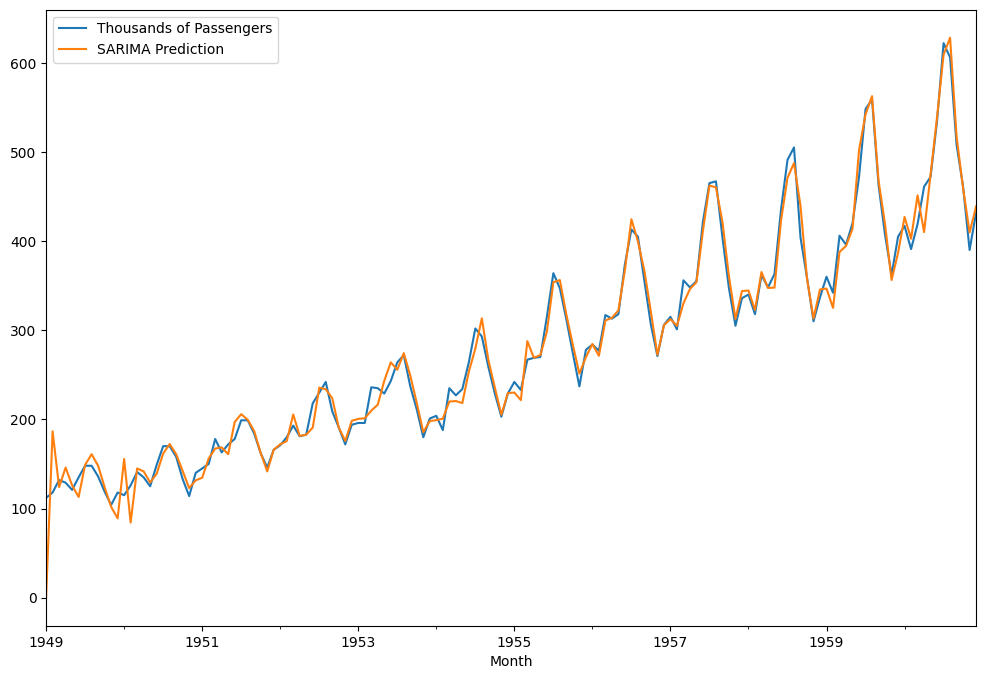

In [59]:
df_airline[["Thousands of Passengers", "SARIMA Prediction"]].plot(figsize = (12,8))

**According to the visual Analysis, we can say that SARIMA is good for prediction but since we use ARIMA family we need to check if residuals are white noise or not**

### 6. Residuals Diagnostics

<Axes: xlabel='Month'>

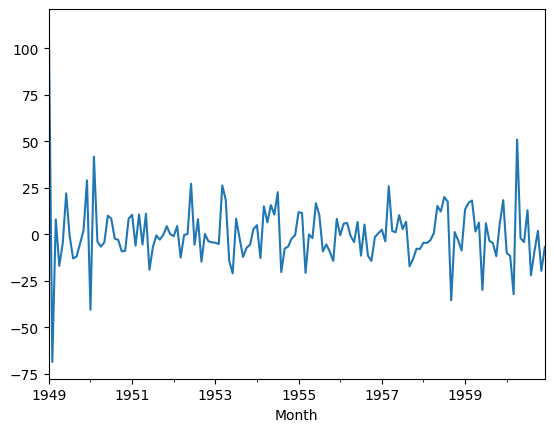

In [62]:
model_SARIMA_fit.resid.plot()

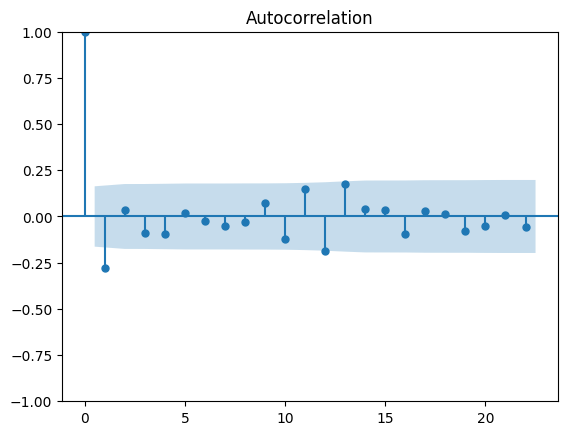

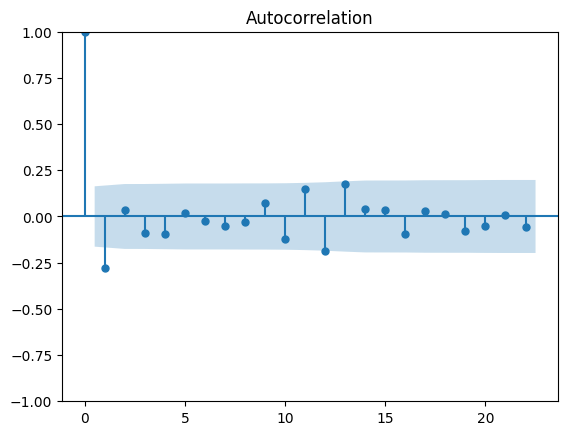

In [63]:
plot_acf(residuals)

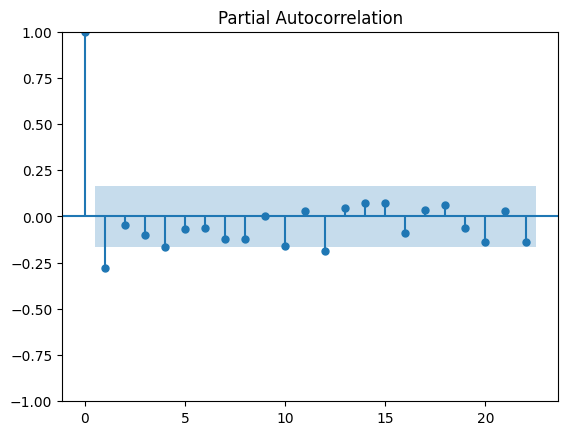

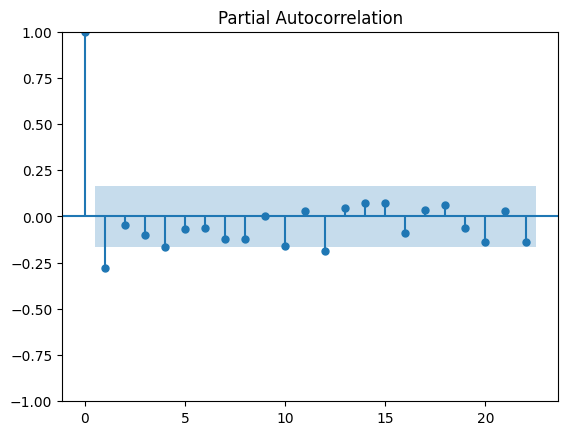

In [64]:
plot_pacf(residuals)

<Axes: ylabel='Density'>

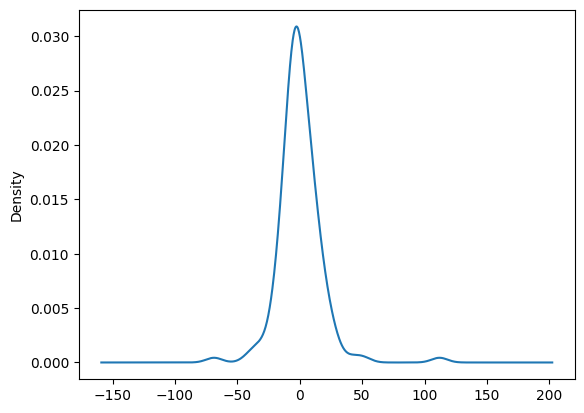

In [65]:
model_SARIMA_fit.resid.plot(kind='kde')

In [66]:
from scipy import stats
stats.jarque_bera(residuals)

SignificanceResult(statistic=np.float64(1053.5914436110806), pvalue=np.float64(1.642573944911322e-229))

**Residuals are not white noise and do not follow normal distribution, so SARIMA is weak to predict future passengers**

### 7. Check Future Values (4 years) using SARIMA

**7.1 Create new rows in our datasets**

In [70]:
from pandas.tseries.offsets import DateOffset
future_dates_s = [df_airline.index[-1] + DateOffset (months = x) for x in range(0, 48)] #48 months is 4 years
future_date_dataset = pd.DataFrame(index = future_dates_s[1:], columns = df_airline.columns)
future_date_dataset.tail()
merged_df_s = pd.concat([df_airline, future_date_dataset])


In [71]:
merged_df_s.tail()

,Thousands of Passengers,Passengers First Difference,Passengers Second Difference,First Difference S,SARIMA Prediction
1964-07-01,NaN,NaN,NaN,NaN,NaN
1964-08-01,NaN,NaN,NaN,NaN,NaN
1964-09-01,NaN,NaN,NaN,NaN,NaN
1964-10-01,NaN,NaN,NaN,NaN,NaN
1964-11-01,NaN,NaN,NaN,NaN,NaN


**7.2 Predict the 4 years**

<Axes: >

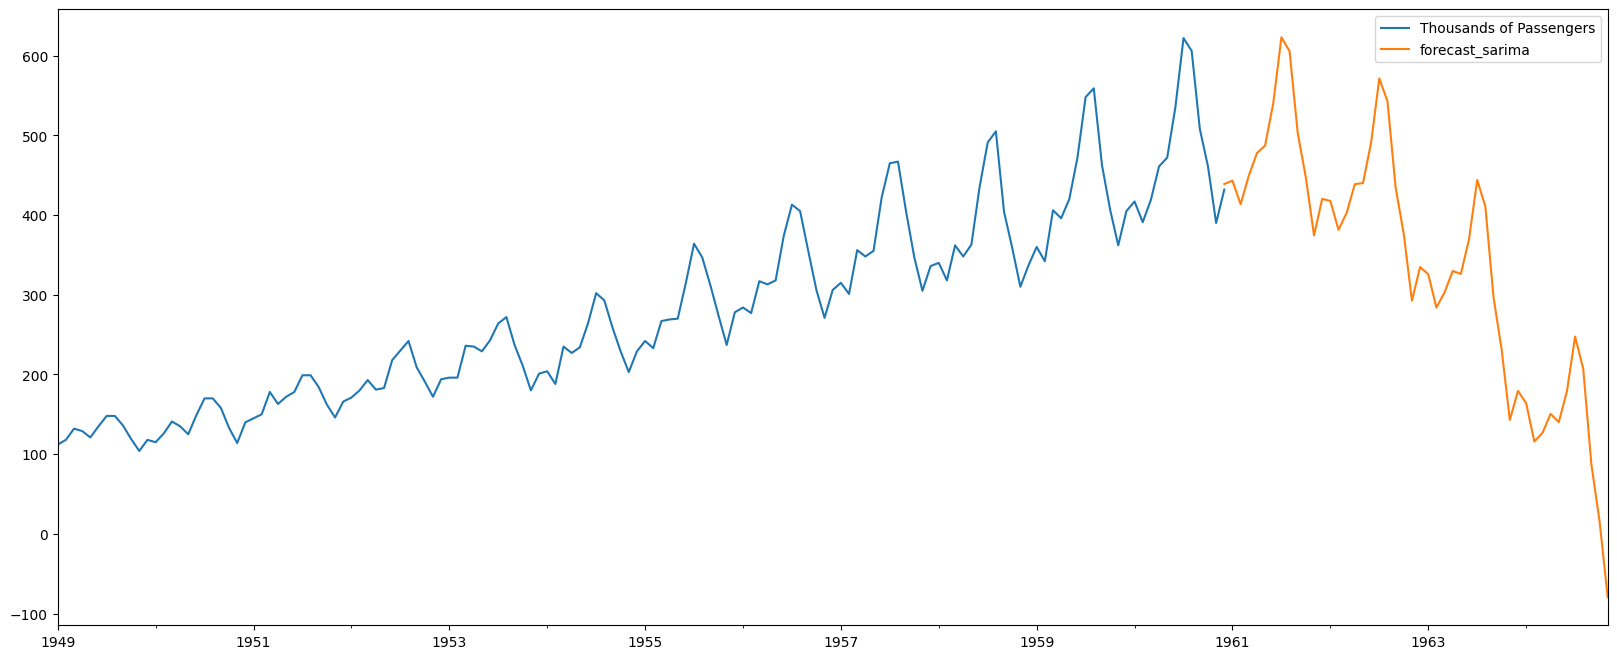

In [72]:
merged_df_s['forecast_sarima'] = model_SARIMA_fit.predict(start ="1960-12-01", end = "1964-12-31", dynamic= True )
merged_df_s[['Thousands of Passengers', 'forecast_sarima']].plot(figsize = (20, 8))

### Final Decision: SARIMA is weak and refused